## Modelado y Predicción de Series de Tiempo

En esta sección se implementan y comparan diferentes enfoques para el pronóstico de las series de tiempo.
El flujo de modelado sigue esta secuencia:

1.-Modelo baseline: Implementación de una Media Móvil simple para establecer un punto de referencia de error mínimo aceptable.

2.- Modelo estadístico donde se hace ajuste y pronóstico utilizando SARIMAX, evaluando previamente los supuestos de la serie.

3.-Ingeniería de características usando la transformación de la serie temporal en un problema de regresión supervisada mediante la creación de lags (rezagos) y ventanas móviles para los modelos basados en árboles.

4.-Modelo de Machine Learning usand entrenamiento de un Random Forest utilizando el dataframe transformado.


Objetivo: Evaluar el desempeño de cada modelo mediante métricas de error (RMSE, MAE) en un set de prueba cronológico, para seleccionar la estrategia de predicción más precisa y justificar la elección del modelo final.

In [1]:
import sys
import subprocess

subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'statsmodels'])

print("Instalación en el entorno correcto.")


Instalación en el entorno correcto.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
from pathlib import Path

In [3]:
df = pd.read_csv(Path("..") / "Datos" / "historico_equipos.csv", index_col=0, parse_dates=True)

### Baseline: Predicción usando Media Móvil

En cualquier proyecto de predicción es fundamental establecer un modelo baseline para poder comparar el desempeño de modelos más complejos. En este caso, utilizamos una Media Móvil por su simplicidad, lo que nos permite además ajustar fácilmente el tamaño de la ventana de observación.

Un detalle crítico en la implementación es evitar el data leakage: no utilizamos el valor del periodo actual para predecir ese mismo periodo, sino que desplazamos la ventana para usar únicamente información pasada.

Para la evaluación de los modelos utilizaremos RMSE y MAE. Al ser un problema de regresión con variable continua, estas métricas son ideales porque el error se expresa en las mismas unidades que la variable objetivo (el precio), lo que facilita mucho la interpretación para el negocio.

In [4]:
variable_objetivo = 'Price_Equipo2' # La otra variable objetivo a trabajar sería 'Price_Equipo2 y se puede cambiar aquí
ventana_dias = 7  # Aquí podemos cambiar el paramétros de la ventana del promediado

df['Prediccion_MM'] = df[variable_objetivo].rolling(window=ventana_dias).mean().shift(1)
df_modelo = df.dropna()
y_real = df_modelo[variable_objetivo]
y_pred = df_modelo['Prediccion_MM']

#métricas
rmse = np.sqrt(mean_squared_error(y_real, y_pred))
mae = mean_absolute_error(y_real, y_pred)

#valor a comprobar con la predicción
ultimo_real = float(y_real.iloc[-1])
ultimo_predicho = float(y_pred.iloc[-1])

# Error absoluto y porcentual
error_absoluto = abs(ultimo_real - ultimo_predicho)

error_porcentual = (error_absoluto / ultimo_real) * 100
print(f"Valor Real del último día: {ultimo_real:.2f} vs Valor Predicho del útimo día: {ultimo_predicho:.2f} con un Error Porcentual:  {error_porcentual:.2f}%")


Valor Real del último día: 955.35 vs Valor Predicho del útimo día: 922.89 con un Error Porcentual:  3.40%


En la celda anterior generamos la primera predicción usando la media móvil.

Las siguientes son las métricas que usaremos con Baseline para comparar con otros modelos.

In [5]:
print(f"--- Métricas del Modelo Media Móvil (Ventana = {ventana_dias}) ---")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"MAE (Mean Absolute Error): {mae:.2f}")

--- Métricas del Modelo Media Móvil (Ventana = 7) ---
RMSE (Root Mean Squared Error): 24.88
MAE (Mean Absolute Error): 18.91


### Visualización de la media móvil

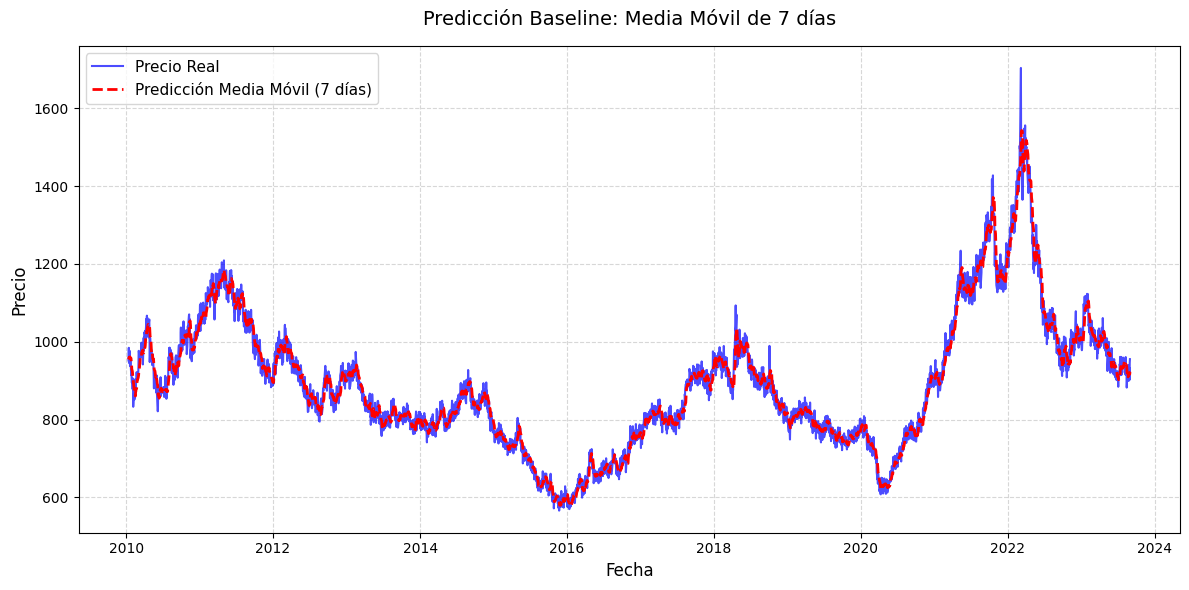

In [6]:
plt.figure(figsize=(12, 6))

# Graficamos los datos reales
plt.plot(df_modelo.index, y_real, label='Precio Real', color='blue', alpha=0.7)

# Graficamos la predicción de la Media Móvil
plt.plot(df_modelo.index, y_pred, label=f'Predicción Media Móvil ({ventana_dias} días)', 
         color='red', linestyle='--', linewidth=2)

plt.title(f'Predicción Baseline: Media Móvil de {ventana_dias} días', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

En la celda anterior generamos la primera predicción usando la media móvil.

### ARIMA (Autoregressive Integrated Moving Average)

Antes de ajustar un modelo ARIMA, es necesario validar si la serie es estacionaria (es decir, que sus propiedades estadísticas no dependan del tiempo). Para definir los parámetros del modelo (p, d, q), combinamos dos enfoques:

Prueba estadística de Dickey-Fuller Aumentada la cuál nos dice objetivamente si la serie requiere diferenciación (parámetro d). Si el p-valor es > 0.05, asumimos que no es estacionaria y debemos diferenciarla.

Inspección visual usando ACF y PACF que nos sirve como guía inicial para estimar los órdenes autorregresivos (p, observado en PACF) y de media móvil (q, observado en ACF), identificando en qué rezagos las correlaciones caen dentro del intervalo de confianza.

In [7]:
#Prueba de estacionario
resultado_adf = adfuller(df[variable_objetivo].dropna(), autolag='AIC')

Estadístico ADF: -1.9064
p-valor: 0.3290
Valores críticos:
{'1%': -3.432207527984423, '5%': -2.862360750792696, '10%': -2.5672068996116435}
CONCLUSIÓN: p-valor > 0.05. La serie NO es estacionaria.


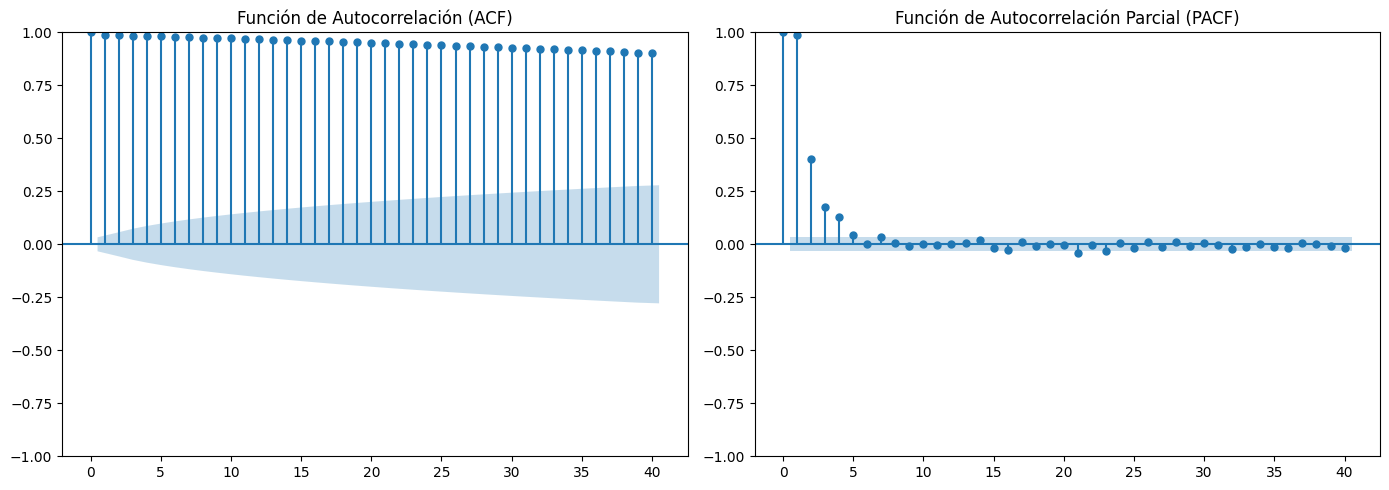

In [8]:
print(f'Estadístico ADF: {resultado_adf[0]:.4f}')
print(f'p-valor: {resultado_adf[1]:.4f}')
print(f'Valores críticos:\n{resultado_adf[4]}')

if resultado_adf[1] <= 0.05:
    print("CONCLUSIÓN: p-valor <= 0.05. La serie es estacionaria.")
    d_sugerida = 0
else:
    print("CONCLUSIÓN: p-valor > 0.05. La serie NO es estacionaria.")
    d_sugerida = 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(df[variable_objetivo].dropna(), lags=40, ax=axes[0], alpha=0.05)
axes[0].set_title('Función de Autocorrelación (ACF)')

plot_pacf(df[variable_objetivo].dropna(), lags=40, ax=axes[1], alpha=0.05)
axes[1].set_title('Función de Autocorrelación Parcial (PACF)')

plt.tight_layout()
plt.show()

In [9]:
dias_test = 30 
train = df.iloc[:-dias_test]
test = df.iloc[-dias_test:]
orden_arima = (1, d_sugerida, 1) 

print(f"\nEntrenando modelo SARIMAX con orden {orden_arima}...")

modelo = SARIMAX(train[variable_objetivo], 
                 order=orden_arima,
                 enforce_stationarity=False, 
                 enforce_invertibility=False)

resultados = modelo.fit(disp=False)
predicciones_arima = resultados.get_forecast(steps=dias_test).predicted_mean


Entrenando modelo SARIMAX con orden (1, 1, 1)...


c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a m

In [10]:
y_real_test = test[variable_objetivo]

# Métricas para ARIMA (se compararan con Media móvil)
rmse_arima = np.sqrt(mean_squared_error(y_real_test, predicciones_arima))
mae_arima = mean_absolute_error(y_real_test, predicciones_arima)

rmse_mm_referencia = rmse
mae_mm_referencia = mae  

print("COMPARATIVA DE MODELOS (Set de Test)")
print(f"{'Modelo':<25} | {'RMSE':<15} | {'MAE':<15}")
print("-"*60)
print(f"{'Baseline (Media Móvil)':<25} | {rmse_mm_referencia:<15.2f} | {mae_mm_referencia:<15.2f}")
print(f"{'ARIMA {orden_arima}':<25} | {rmse_arima:<15.2f} | {mae_arima:<15.2f}")


COMPARATIVA DE MODELOS (Set de Test)
Modelo                    | RMSE            | MAE            
------------------------------------------------------------
Baseline (Media Móvil)    | 24.88           | 18.91          
ARIMA {orden_arima}       | 21.76           | 18.63          


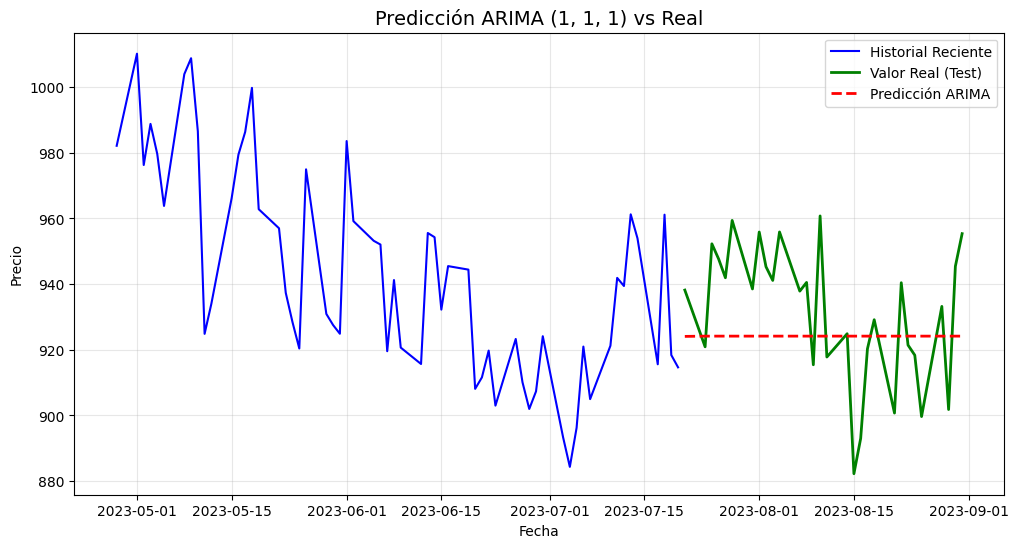

In [11]:
# Visualización de la predicción
plt.figure(figsize=(12, 6))
plt.plot(train.index[-60:], train[variable_objetivo].iloc[-60:], label='Historial Reciente', color='blue')
plt.plot(test.index, y_real_test, label='Valor Real (Test)', color='green', linewidth=2)
plt.plot(test.index, predicciones_arima, label='Predicción ARIMA', color='red', linestyle='--', linewidth=2)

plt.title(f'Predicción ARIMA {orden_arima} vs Real', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True, alpha=0.3)

## Random Forest

Los algoritmos basados en árboles como Random Forest no interpretan el orden temporal de forma nativa; para ellos, cada fila es una observación independiente.

Para aplicarlos a series de tiempo, es necesario transformar el problema en un formato de aprendizaje supervisado (tabular). Esto implica construir un nuevo dataframe mediante ingeniería de características, donde los valores pasados y estadísticas rodantes se convierten en las variables predictoras, y el valor actual actúa como la variable objetivo.

Este paso es crítico para evitar el data leakage, ya que debemos garantizar que el modelo solo utilice información histórica disponible en el momento de la predicción.

Se usa Random Forest para capturar relaciones no lineales en la serie.

In [12]:
def crear_features(df, target_col):
    df_feat = df.copy()
    
    df_feat['lag_1'] = df_feat[target_col].shift(1)
    df_feat['lag_7'] = df_feat[target_col].shift(7)
    df_feat['lag_30'] = df_feat[target_col].shift(30)
    df_feat['rolling_mean_7'] = df_feat[target_col].shift(1).rolling(window=7).mean()
    df_feat['rolling_std_7'] = df_feat[target_col].shift(1).rolling(window=7).std()
    
    if isinstance(df_feat.index, pd.DatetimeIndex):
        df_feat['mes'] = df_feat.index.month
        df_feat['dia_semana'] = df_feat.index.dayofweek
        df_feat['es_fin_de_semana'] = df_feat['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)
    
    df_feat = df_feat.dropna()
    return df_feat

df_ml = crear_features(df, variable_objetivo)

### Preparación de datos train y test en orden cronológico
Es imporante recordar que como estamos trabajando con series de tiempo el train_test_split NUNCA puede ser aleatorio, ya que justamente esta la dependencia temporal.

En este caso usamos los últimos 30 días como test que es el horizonte de predicción.

In [13]:
dias_test = 30
train = df_ml.iloc[:-dias_test]
test = df_ml.iloc[-dias_test:]
features = [col for col in train.columns if col != variable_objetivo]
X_train, y_train = train[features], train[variable_objetivo]
X_test, y_test = test[features], test[variable_objetivo]


In [14]:
modelo_rf = RandomForestRegressor(
    n_estimators=100,      # Número de árboles (Hiperparámetro)
    max_depth=10,          # Profundidad máxima (Hiperparámetro)
    min_samples_split=5,  
    random_state=42,
    n_jobs=-1              
)

modelo_rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_split=5, n_jobs=-1,
                      random_state=42)

Evaluación y comparación de modelos

In [15]:
predicciones_rf = modelo_rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, predicciones_rf))
mae_rf = mean_absolute_error(y_test, predicciones_rf)

print("COMPARATIVA DE MODELOS (Set de Test)")
print("="*60)
print(f"{'Modelo':<25} | {'RMSE':<15} | {'MAE':<15}")
print("-"*60)
print(f"{'Baseline (Media Móvil)':<25} | {rmse:<15.2f} | {mae:<15.2f}")
print(f"{'ARIMA (1,1,1)':<25} | {rmse_arima:<15.2f} | {mae_arima:<15.2f}")
print(f"{'Random Forest':<25} | {rmse_rf:<15.2f} | {mae_rf:<15.2f}")
print("="*60)



COMPARATIVA DE MODELOS (Set de Test)
Modelo                    | RMSE            | MAE            
------------------------------------------------------------
Baseline (Media Móvil)    | 24.88           | 18.91          
ARIMA (1,1,1)             | 21.76           | 18.63          
Random Forest             | 16.19           | 13.20          


###  Conclusiones de la Comparativa
Los resultados muestran una mejora progresiva clara entre los tres modelos:
1. Baseline (Media Móvil): RMSE 24.88, MAE 18.91
Este es nuestro punto de referencia. Cualquier modelo que usemos debe superar estos números para justificar su complejidad. La media móvil suaviza la señal pero no captura patrones complejos ni estacionalidad.

2. ARIMA (1,1,1): RMSE 21.76, MAE 18.63
Mejora modesta sobre el baseline (~12% en RMSE). El modelo estadístico captura la estructura temporal (tendencia y autocorrelación), pero su mejora limitada sugiere que la relación entre las variables no es puramente lineal o que los parámetros (1,1,1) podrían no ser óptimos por lo que se proponer usar otros parámetros.

3. Random Forest: RMSE 16.19, MAE 13.20
El mejor desempeño con una mejora significativa (~35% en RMSE vs baseline, ~25% vs ARIMA). Esto indica que las relaciones en los datos tienen componentes no lineales o interacciones entre variables que los árboles capturan bien pero ARIMA no.

Con Random Forest, en promedio nos equivocamos por ~13 unidades de precio (MAE)
El error cuadrático medio es ~16 unidades (RMSE), lo que significa que los errores grandes pesan más
Si el precio promedio del equipo es ~500 (ejemplo), un MAE de 13 representa un error relativo de ~2.6%, que es bastante bueno para predicción de precios

Visualización de los resultados

C:\Users\Selene\AppData\Local\Temp\ipykernel_24224\1581846192.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Feature', data=df_importancias, ax=axes[1], palette='viridis')


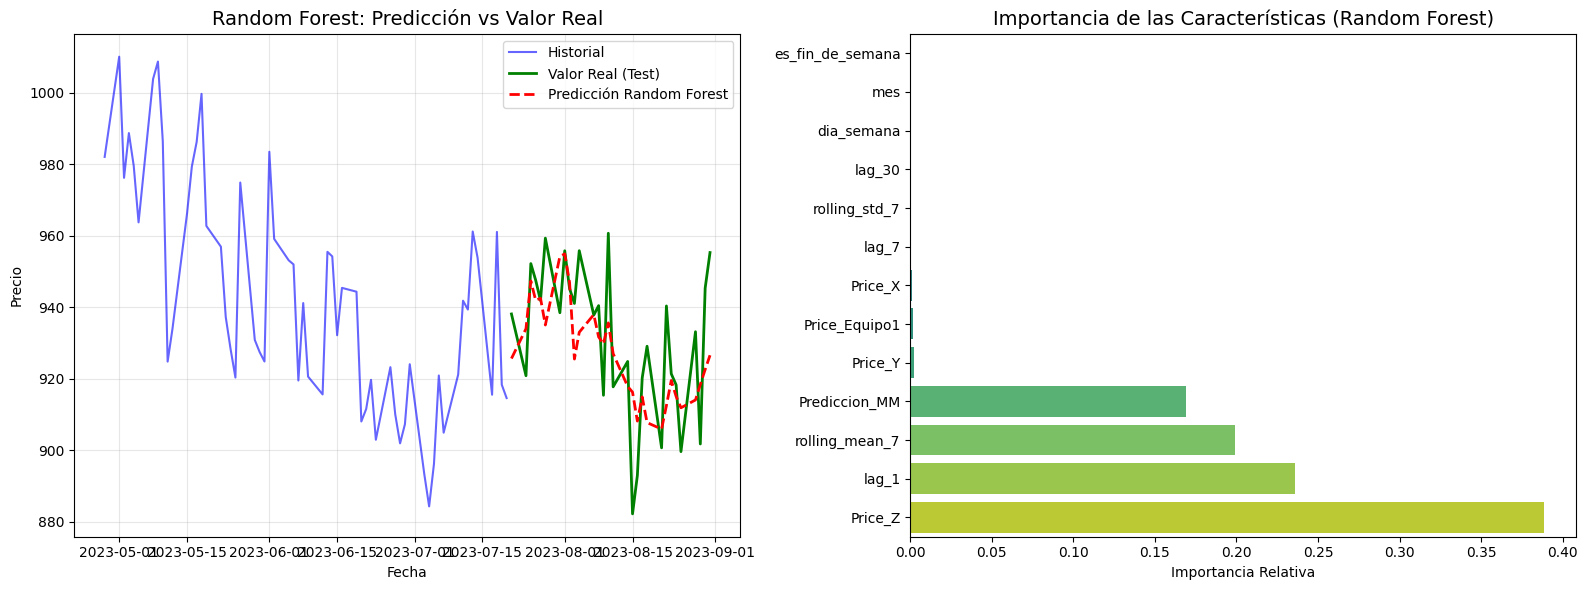

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Predicción vs Real
axes[0].plot(train.index[-60:], train[variable_objetivo].iloc[-60:], label='Historial', color='blue', alpha=0.6)
axes[0].plot(test.index, y_test, label='Valor Real (Test)', color='green', linewidth=2)
axes[0].plot(test.index, predicciones_rf, label='Predicción Random Forest', color='red', linestyle='--', linewidth=2)
axes[0].set_title('Random Forest: Predicción vs Valor Real', fontsize=14)
axes[0].set_xlabel('Fecha')
axes[0].set_ylabel('Precio')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

#Importancia de las Features usando RF
importancias = modelo_rf.feature_importances_
df_importancias = pd.DataFrame({'Feature': features, 'Importancia': importancias})
df_importancias = df_importancias.sort_values(by='Importancia', ascending=True)

sns.barplot(x='Importancia', y='Feature', data=df_importancias, ax=axes[1], palette='viridis')
axes[1].set_title('Importancia de las Características (Random Forest)', fontsize=14)
axes[1].set_xlabel('Importancia Relativa')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()



 ### Prediccion a futuro

 Se crea un DataFrame de una sola fila con las features calculadas a partir del último dato real

In [18]:
ultimo_registro_real = df.iloc[-1]


features_futuro = pd.DataFrame({
    'lag_1': [ultimo_registro_real[variable_objetivo]],
    'lag_7': [df.iloc[-7][variable_objetivo]],
    'lag_30': [df.iloc[-30][variable_objetivo]],
    'rolling_mean_7': [df.iloc[-7:][variable_objetivo].mean()],
    'rolling_std_7': [df.iloc[-7:][variable_objetivo].std()],
    'mes': [pd.to_datetime(ultimo_registro_real.name).month], # Ajusta si tu índice no es datetime
    'dia_semana': [pd.to_datetime(ultimo_registro_real.name).dayofweek],
    'es_fin_de_semana': [1 if pd.to_datetime(ultimo_registro_real.name).dayofweek >= 5 else 0]
})

In [19]:
features_futuro = df_ml.iloc[[-1]].copy()

features_futuro = features_futuro[features]

prediccion_futura_rf = modelo_rf.predict(features_futuro)[0]

print(f"Predicción usando RF")
print(f"Variable: {variable_objetivo}")
print(f"Valor predicho: {prediccion_futura_rf:.2f} vs último valor real: {ultimo_registro_real[variable_objetivo]:.2f}")

Predicción usando RF
Variable: Price_Equipo2
Valor predicho: 926.62 vs último valor real: 955.35


### Margen de error para las predicciones
Las métricas RMSE y MAE nos indican el error promedio del modelo, pero para decisiones de negocio necesitamos conocer el rango de incertidumbre de cada predicción individual.

Para Random Forest, aprovechamos la naturaleza del ensemble: cada uno de los árboles del bosque produce una predicción ligeramente diferente. Calculamos la desviación estándar entre estas predicciones individuales y construimos un intervalo de confianza aproximado del 95% (media ± 1.96 × desviación estándar).

In [20]:
predicciones_arboles = np.array([arbol.predict(X_test) for arbol in modelo_rf.estimators_])

prediccion_media = predicciones_arboles.mean(axis=0)
desviacion = predicciones_arboles.std(axis=0)

# Intervalo de confianza aproximado (95%)
limite_inferior = prediccion_media - 1.96 * desviacion
limite_superior = prediccion_media + 1.96 * desviacion

print(f"Predicción: {prediccion_media[0]:.2f}")
print(f"Margen de error (95%): [{limite_inferior[0]:.2f}, {limite_superior[0]:.2f}]")

Predicción: 925.70
Margen de error (95%): [892.26, 959.14]


c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Selene\miniconda3\envs\flores-mlops\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Selene\miniconda3\env